# Titanic Survival Analysis
### Exploratory Data Analysis, Cleaning & Visualization

**Question:** How do survival rates differ across passenger groups, and what patterns are visible in the Titanic training dataset?

This portfolio project extends an introductory Pandas lab into a small exploratory analysis with charts and written findings. It is **not** a predictive model, and correlations here do not demonstrate causation.

**Tools:** Python · Pandas · NumPy · Matplotlib · Seaborn

**Data:** Titanic passenger training records (891 observations), supplied for a university lab; see the dataset credit in `README.md`.

## 1. Load and inspect the data

The notebook works when run from either the repository root or the `notebooks/` directory.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 115

# Support both launching Jupyter from the repository root and from notebooks/.
candidates = [Path("data/titanic.csv"), Path("../data/titanic.csv")]
csv_path = next((p for p in candidates if p.exists()), None)
if csv_path is None:
    raise FileNotFoundError("Dataset missing: place titanic.csv inside the data/ directory.")
project_dir = csv_path.resolve().parent.parent
figures_dir = project_dir / "figures"
figures_dir.mkdir(exist_ok=True)

df = pd.read_csv(csv_path)
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Data quality audit

Check missing observations and repeated identifiers **before** cleaning. The passenger records are retained, while incomplete fields are handled using simple, transparent rules.

In [2]:
missing_report = (pd.DataFrame({
    "Missing": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2)
}).query("Missing > 0").sort_values("Missing", ascending=False))
display(missing_report)
print("Duplicate rows:", df.duplicated().sum())
print("Repeated passenger IDs:", df["PassengerId"].duplicated().sum())

,Missing,Missing (%)
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


Duplicate rows: 0
Repeated passenger IDs: 0


**Cleaning choices:** `Age` has 177 missing values, so fill with its median (28); `Embarked` has 2 missing values, so fill with its mode (`S`). Drop `Cabin` because 687 of 891 entries (77.10%) are missing. Median imputation is convenient but changes the apparent age distribution; later age-based comparisons must be interpreted with this limitation in mind.

In [3]:
work_df = df.copy()
median_age = work_df["Age"].median()
mode_embarked = work_df["Embarked"].mode().iloc[0]

work_df["Age"] = work_df["Age"].fillna(median_age)
work_df["Embarked"] = work_df["Embarked"].fillna(mode_embarked)
work_df = work_df.drop(columns=["Cabin"])

assert len(work_df) == len(df)
assert work_df["PassengerId"].is_unique
assert work_df.isna().sum().sum() == 0
print("Cleaned shape:", work_df.shape)
print("Remaining missing values:", work_df.isna().sum().sum())
print("Age median:", median_age, "| Embarked mode:", mode_embarked)

Cleaned shape: (891, 11)
Remaining missing values: 0
Age median: 28.0 | Embarked mode: S


## 3. Create features and summarize survival

Features follow the original lab logic: **FamilySize**, **IsAlone**, and **HighFare** (fare strictly above the dataset median). An **AgeGroup** is added to compare broad age categories.

In [4]:
work_df["FamilySize"] = work_df["SibSp"] + work_df["Parch"] + 1
work_df["IsAlone"] = (work_df["FamilySize"] == 1).astype(int)
work_df["HighFare"] = work_df["Fare"] > work_df["Fare"].median()
work_df["AgeGroup"] = pd.cut(
    work_df["Age"], bins=[0, 12, 18, 60, np.inf],
    labels=["Child (0–12)", "Teen (13–18)", "Adult (19–60)", "Senior (61+)"] ,
    include_lowest=True
)

survival_rate = 100 * work_df["Survived"].mean()
sex_rates = (100 * work_df.groupby("Sex")["Survived"].mean()).round(2)
class_rates = (100 * work_df.groupby("Pclass")["Survived"].mean()).round(2)
fare_rates = (100 * work_df.groupby("HighFare")["Survived"].mean()).round(2)
age_rates = (100 * work_df.groupby("AgeGroup", observed=True)["Survived"].mean()).round(2)

print(f"Survived: {int(work_df['Survived'].sum())} / {len(work_df)} ({survival_rate:.2f}%)")
print("\nBy sex (%):\n", sex_rates.to_string())
print("\nBy class (%):\n", class_rates.to_string())
print("\nBy high-fare group (%):\n", fare_rates.to_string())
print("\nBy age group (%):\n", age_rates.to_string())

Survived: 342 / 891 (38.38%)

By sex (%):
 Sex
female    74.20
male      18.89

By class (%):
 Pclass
1    62.96
2    47.28
3    24.24

By high-fare group (%):
 HighFare
False    25.06
True     51.80

By age group (%):
 AgeGroup
Child (0–12)     57.97
Teen (13–18)     42.86
Adult (19–60)    36.58
Senior (61+)     22.73


## 4. Chart: survival rates across four groups

Each bar is the fraction of passengers within that group whose `Survived` value is `1`. Percentages are compared using the same 0–100% scale.

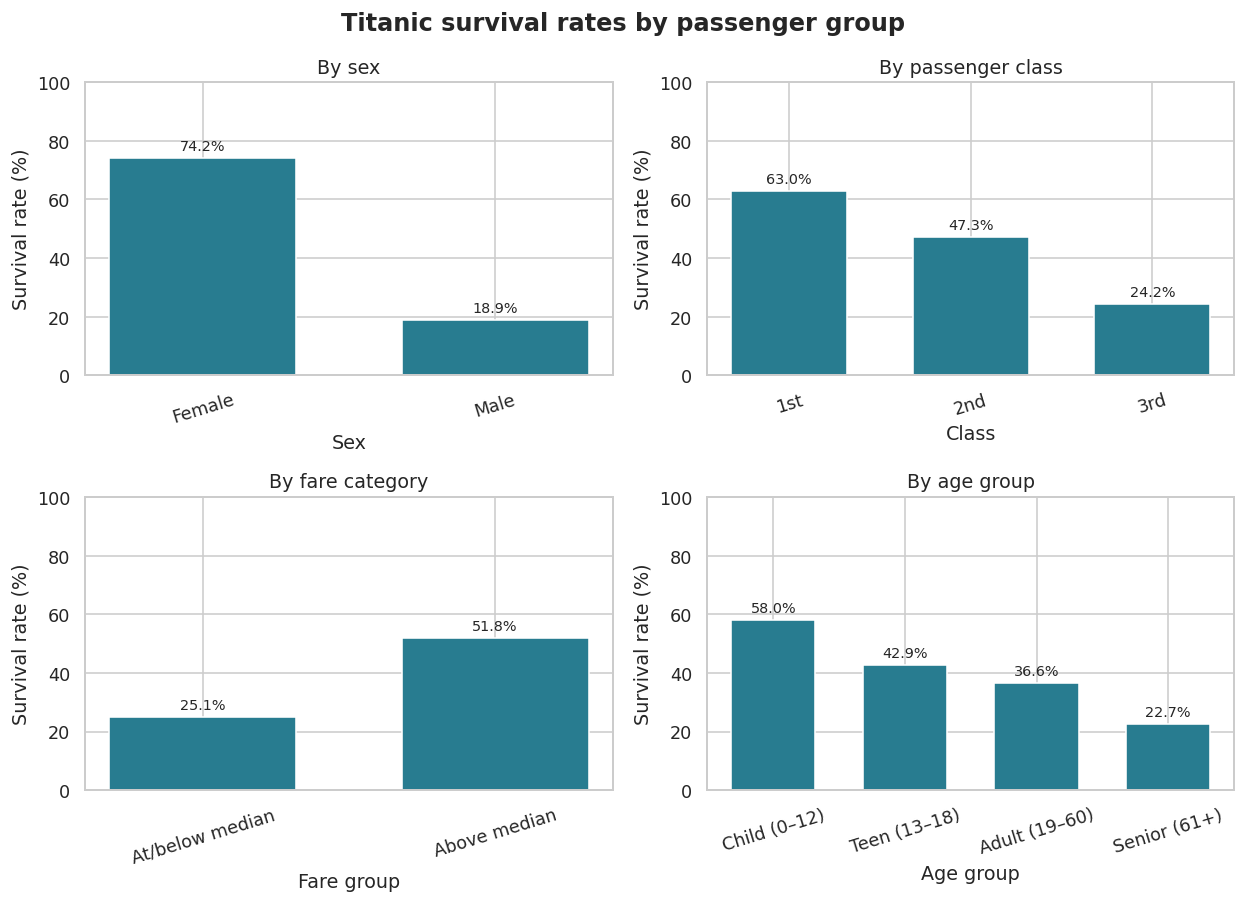

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
charts = [
    (sex_rates.rename(index={"female": "Female", "male": "Male"}), "By sex", "Sex"),
    (class_rates.rename(index={1: "1st", 2: "2nd", 3: "3rd"}), "By passenger class", "Class"),
    (fare_rates.rename(index={False: "At/below median", True: "Above median"}), "By fare category", "Fare group"),
    (age_rates, "By age group", "Age group")
]
for ax, (rates, title, xlabel) in zip(axes.flat, charts):
    bars = ax.bar([str(v) for v in rates.index], rates.to_numpy(), color="#287C90", width=0.64)
    ax.set(title=title, xlabel=xlabel, ylabel="Survival rate (%)", ylim=(0, 100))
    ax.tick_params(axis="x", labelrotation=17)
    for bar, pct in zip(bars, rates.to_numpy()):
        ax.annotate(f"{pct:.1f}%", (bar.get_x() + bar.get_width()/2, bar.get_height()),
                    ha="center", va="bottom", fontsize=9, xytext=(0, 3), textcoords="offset points")
fig.suptitle("Titanic survival rates by passenger group", fontsize=15, fontweight="bold")
fig.tight_layout()
fig.savefig(figures_dir / "survival_by_group.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. Chart: age distributions by outcome

This comparison uses ages after median imputation. The large stack near age 28 is partly an artifact of that cleaning step, not necessarily an underlying demographic pattern.

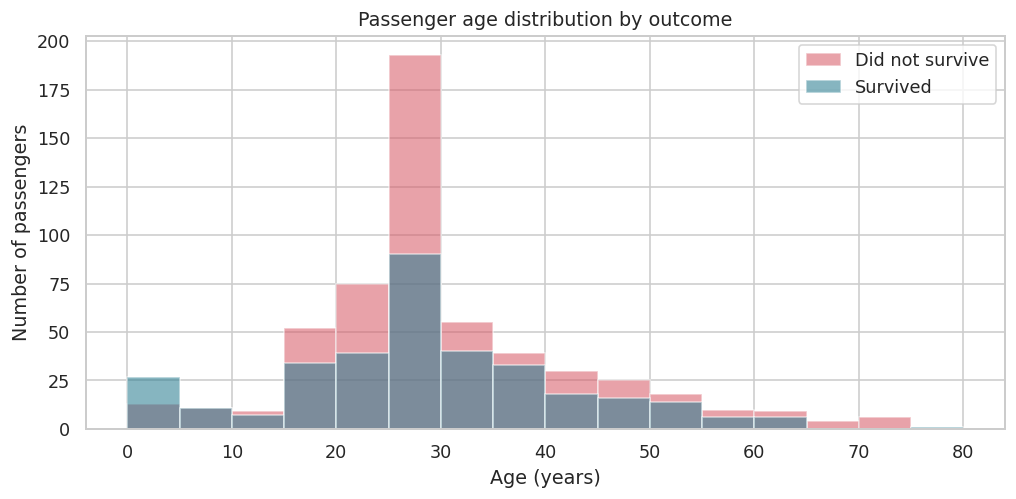

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for survived, label, color in [(0, "Did not survive", "#D65A66"), (1, "Survived", "#287C90")]:
    ages = work_df.loc[work_df["Survived"] == survived, "Age"]
    ax.hist(ages, bins=np.arange(0, 85, 5), alpha=0.56, color=color, label=label, edgecolor="white")
ax.set(title="Passenger age distribution by outcome", xlabel="Age (years)", ylabel="Number of passengers")
ax.legend(frameon=True)
fig.tight_layout()
fig.savefig(figures_dir / "age_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. Chart: a multidimensional view of age, fare, and family size

A bubble chart shows **Age** on the x-axis, log-transformed **Fare** on the y-axis (because fares are highly skewed), **FamilySize** through marker size, and survival outcome through color. It is useful for exploring patterns, not for proving that any feature causes survival.

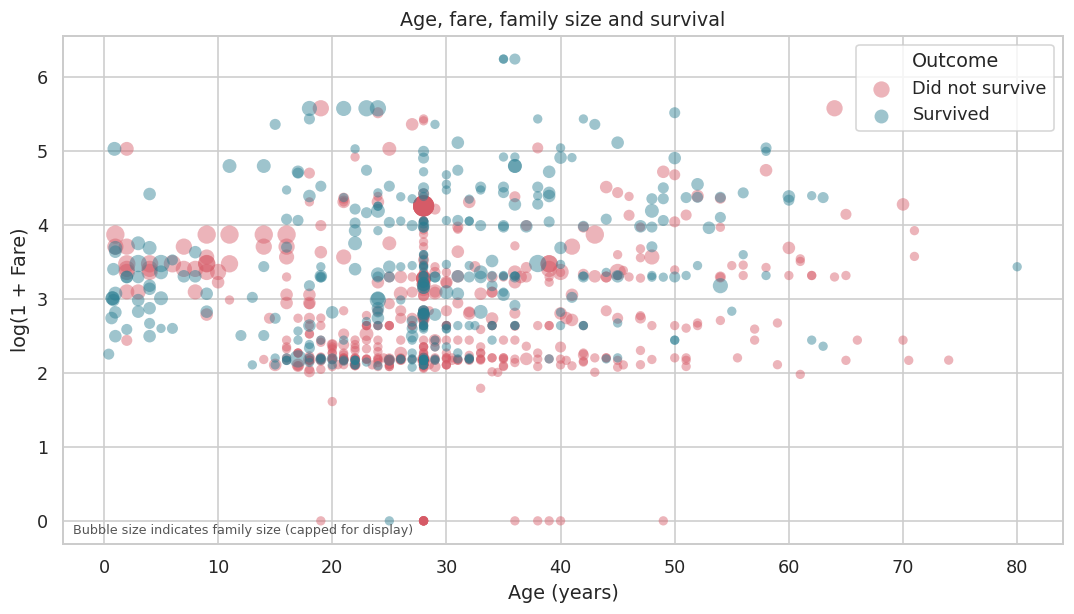

In [7]:
fig, ax = plt.subplots(figsize=(9.5, 5.5))
colors = {0: "#D65A66", 1: "#287C90"}
for survived, label in [(0, "Did not survive"), (1, "Survived")]:
    part = work_df[work_df["Survived"] == survived]
    ax.scatter(part["Age"], np.log1p(part["Fare"]),
               s=20 + 14 * np.minimum(part["FamilySize"], 11),
               c=colors[survived], alpha=0.45, label=label, linewidths=0)
ax.set(title="Age, fare, family size and survival", xlabel="Age (years)", ylabel="log(1 + Fare)")
ax.legend(title="Outcome", loc="upper right")
ax.text(0.01, 0.02, "Bubble size indicates family size (capped for display)",
        transform=ax.transAxes, fontsize=8, color="#555555")
fig.tight_layout()
fig.savefig(figures_dir / "age_fare_bubble.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. Chart: numerical correlation heatmap

Pearson correlations describe **linear association**. `Pclass` is numerically coded but represents categories; the resulting coefficient should be interpreted with care. A large correlation does not establish cause and effect.

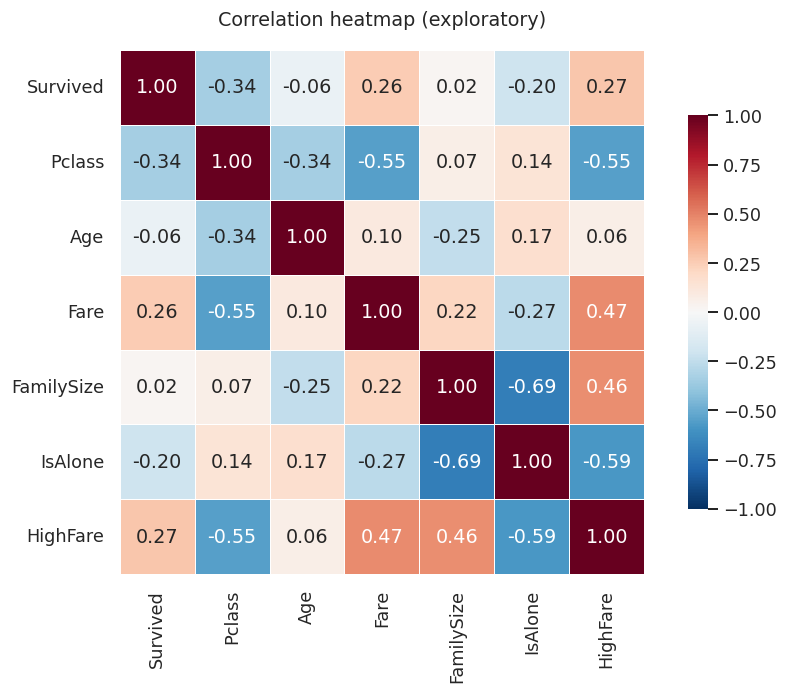

In [8]:
numeric_cols = ["Survived", "Pclass", "Age", "Fare", "FamilySize", "IsAlone", "HighFare"]
correlation_df = work_df[numeric_cols].copy()
correlation_df["HighFare"] = correlation_df["HighFare"].astype(int)
corr = correlation_df.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(8.5, 6.2))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=0.5, linecolor="white", square=True, cbar_kws={"shrink": 0.75}, ax=ax)
ax.set_title("Correlation heatmap (exploratory)", pad=15)
fig.tight_layout()
fig.savefig(figures_dir / "correlation_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()

## 8. Export and validate cleaned data

The exported file retains all 891 passengers, includes the engineered features, and has no missing values after the selected cleaning strategy.

In [9]:
output_path = project_dir / "data" / "titanic_cleaned.csv"
work_df.to_csv(output_path, index=False)
verified = pd.read_csv(output_path)
assert verified.shape == work_df.shape
assert verified.isna().sum().sum() == 0
print("Exported:", output_path.name)
print("Rows, columns:", verified.shape)
print("Missing cells:", int(verified.isna().sum().sum()))

Exported: titanic_cleaned.csv
Rows, columns: (891, 15)
Missing cells: 0


## 9. Key findings and limitations

**Key findings from these records**

1. **Overall:** 342 out of 891 passengers survived (**38.38%**).
2. **Sex:** The observed survival rate was about **74.20% for women**, versus **18.89% for men**.
3. **Passenger class:** Survival rates were **62.96% in first class**, **47.28% in second**, and **24.24% in third**.
4. **Fare group:** Passengers paying more than the median fare had an observed survival rate of **51.80%**, compared with **25.06%** for passengers paying at or below the median.

**Limitations**

- These are historical associations from a single Titanic sample, not causal effects.
- Replacing missing ages with the median affects age-distribution and age-group comparisons.
- Ticket fare is related to passenger class and other factors; the fare comparison does not isolate an independent effect.
- The project focuses on EDA, not predictive-model accuracy or inference about all Titanic passengers.

**Next steps:** Explore missing-data sensitivity, compare within ticket classes, and investigate interaction patterns rather than treating group differences as causal.